# Freddy: SOLO depth structure from the 2015 ADCP crossings

Apply ESP SOLO independently to the **9 supplied transects** through Freddy, then inspect the centre trajectory and Gaussian reconstruction at each measured depth. The shared helper, plot conventions and diagnostics match the 2021 workflow.

[transects.json](transects.json) is the source of data location, UTC transect windows and published MOCA centres used as initial guesses. These are a SOLO application, not a reproduction of MOCA or its confidence intervals. Both 2015 eddies are cyclonic: relative vorticity is negative. “Surface” means the shallowest observed bin within each crossing (30.4 m for OS75; OS150 can reach 18.5 m).

Reference: Roughan et al. (2017), [doi:10.1002/2016JC012241](https://doi.org/10.1002/2016JC012241), section 3.2, Table 4 and Figure 10. Crossings remain separate because eddies translate during the sampling period.

**Saved-output provenance:** executed locally on 13 October 2026 using a copy of the Katana CSV and the ESP backend. Production data paths remain in the source for Katana reruns; input/helper fingerprints and runtime versions are stored in notebook metadata.


In [1]:
from pathlib import Path
import importlib.util
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the shared helper from the study folder or the UNSW-PhD repository root.
candidates = [Path.cwd(), *Path.cwd().parents,
              Path.cwd() / "seacofs_eddy_tilt_analysis" / "observations"]
OBSERVATIONS_DIR = next(p for p in candidates
                        if p.name == "observations" and (p / "esp_depth_tools.py").is_file())
spec = importlib.util.spec_from_file_location("esp_depth_tools", OBSERVATIONS_DIR / "esp_depth_tools.py")
esp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(esp)


## Controls

Edit `freddy_solo.json` for notebook settings and `transects.json` for crossing windows and coordinate origins. Rerun this notebook's SOLO export before buffered LATTE when a crossing changes. `ACTIVE_TRANSECT` selects the detailed figures after all selected crossings have been fitted.


In [2]:
EDDY = "Freddy"
STUDY_DIR = OBSERVATIONS_DIR / "MNF_IN2015_V03_adcp_trawler"
CONFIG_PATH = STUDY_DIR / "freddy_solo.json"
CONFIG = json.loads(CONFIG_PATH.read_text())
TRANSECTS_PATH = STUDY_DIR / CONFIG["transects_config"]
BACKEND_PATH = Path(CONFIG["backend_path"])
VISIT = CONFIG["visit"]  # Edit visit in freddy_solo.json.
if VISIT not in ("visit1", "visit2", "both"):
    raise ValueError("VISIT must be visit1, visit2 or both")
ACTIVE_TRANSECT = CONFIG["active_transect_by_visit"][VISIT]
OVERVIEW_BOUNDS = CONFIG["overview_bounds_by_visit"][VISIT]
DATA_PATH, transects, adcp = esp.load_study(
    TRANSECTS_PATH, EDDY, overview_bounds=OVERVIEW_BOUNDS)
visit_ids = [f"F{i}" for i in (range(1, 8) if VISIT == "visit1"
             else range(8, 10) if VISIT == "visit2" else range(1, 10))]
transects = transects.loc[visit_ids]
if ACTIVE_TRANSECT not in transects.index:
    raise ValueError(f"ACTIVE_TRANSECT must be one of {list(transects.index)}")
MIN_ATTENDANCE = CONFIG["min_attendance"]
FIT = CONFIG["fit"]
MAP_DEPTHS = tuple(CONFIG["map_depths"])
HALF_WIDTH_KM = CONFIG["half_width_km"]
VELOCITY_LIMIT = CONFIG["velocity_limit"]
display(transects)


,eddy,start,end,lon,lat
id,,,,,
F1,Freddy,2015-06-08T22:15:00Z,2015-06-09T01:55:00Z,153.2057,-32.5763
F2,Freddy,2015-06-09T03:00:00Z,2015-06-09T04:30:00Z,153.1891,-32.5825
F3,Freddy,2015-06-09T05:50:00Z,2015-06-09T07:20:00Z,153.2188,-32.5691
F4,Freddy,2015-06-09T13:45:00Z,2015-06-09T14:45:00Z,153.2487,-32.6099
F5,Freddy,2015-06-09T21:00:00Z,2015-06-09T22:30:00Z,153.2435,-32.6550
F6,Freddy,2015-06-10T02:15:00Z,2015-06-10T03:15:00Z,153.2461,-32.6425
F7,Freddy,2015-06-12T15:30:00Z,2015-06-12T17:00:00Z,153.4448,-32.8224
F8,Freddy,2015-06-16T15:30:00Z,2015-06-16T16:30:00Z,153.9855,-33.2769
F9,Freddy,2015-06-16T23:00:00Z,2015-06-17T00:00:00Z,153.8311,-33.2702


(np.float64(152.76250399999998),
 np.float64(153.66683600000002),
 np.float64(-32.888024),
 np.float64(-32.272596))

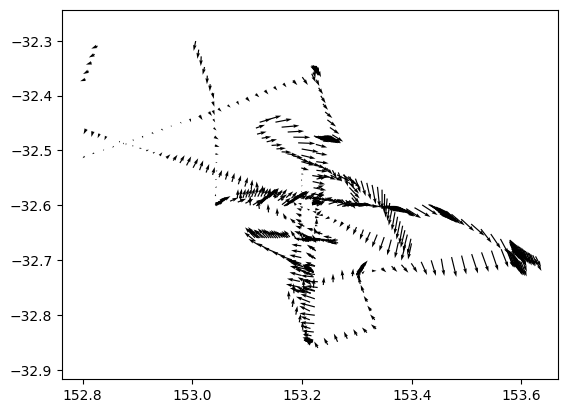

In [3]:
target_depth = adcp.Depth.value_counts().idxmax()
df = adcp[adcp.Depth==target_depth].copy()
plt.quiver(df.lon, df.lat, df.u, df.v)
plt.axis('equal')

## Fit all crossings independently

At each depth, SOLO estimates the circular-core centre and rotation. Accepted inner centres initialise the next depth, while rejected bins remain gaps. The Gaussian radius fit is evaluated separately: centre profiles remain available when radius is unsupported. By default the sampled normalised radius must straddle `Rc/sqrt(2)` for a full reconstruction.

These short MOCA windows may not sample the outer velocity decay. The acceptance table makes that limitation explicit. No averaging across crossings, depth interpolation, background subtraction, or movement correction is performed. Counts and R² are diagnostics, not independent validation.


path                 /home/z5297792/ESP_zonodo/functions.py
sha256    8e4b06fe4c144f7a70671ee913b6d27784f9cdb587e9b0...
Name: ESP backend, dtype: object

,times,bins,inner_fits,gaussian_fits,inner_min_m,inner_max_m,gaussian_max_m,surface_status
transect,,,,,,,,
F1,44,50,47,47,30.4,766.4,766.4,ok
F2,18,50,50,26,30.4,814.4,814.4,outer_radius_limit
F3,18,49,49,32,30.4,798.4,766.4,peak_not_bracketed
F4,12,49,21,0,30.4,350.4,NaN,peak_not_bracketed
F5,18,50,45,39,30.4,734.4,654.4,ok
F6,12,50,32,4,30.4,526.4,142.4,ok
F7,18,28,26,17,34.5,234.5,234.5,peak_not_bracketed
F8,12,35,31,2,18.5,258.5,114.5,outer_radius_limit
F9,12,34,19,0,26.5,186.5,NaN,solo_crossing_at_bound


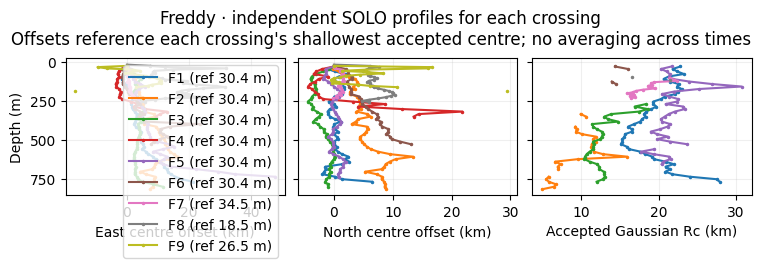

In [4]:
backend, backend_info = esp.load_backend(BACKEND_PATH)
runs, summary, all_results = esp.fit_transects(
    DATA_PATH, transects, backend, FIT, min_attendance=MIN_ATTENDANCE)
display(pd.Series(backend_info, name="ESP backend"))
display(summary)
esp.plot_transect_comparison(runs, EDDY)
plt.show()


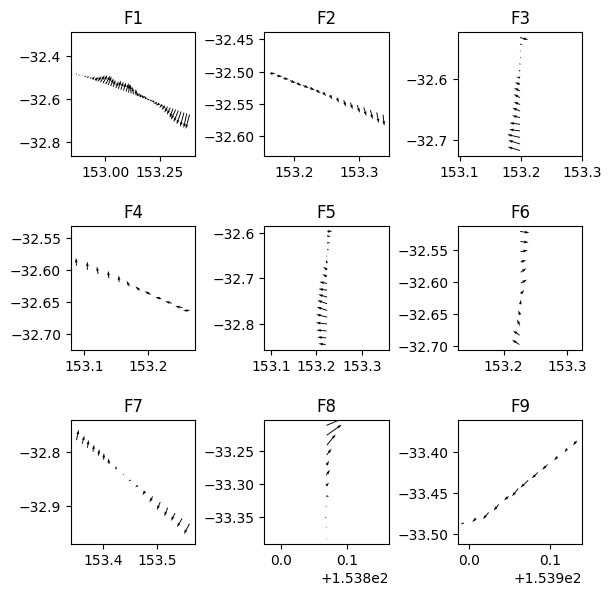

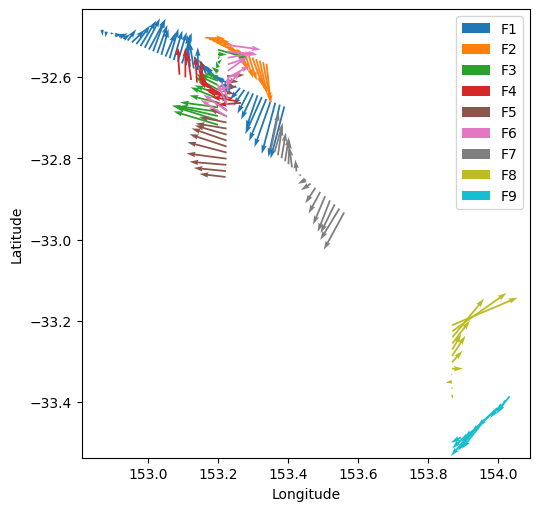

In [5]:
ncols = 3
nrows = int(np.ceil(len(transects) / ncols))
fig, axs = plt.subplots(nrows, ncols, constrained_layout=True,
                        figsize=(2*ncols, 2*nrows), squeeze=False)
for ax, trans in zip(axs.flat, transects.index):
    run = runs[trans]
    sample = run["samples"][run["results"].depth_m.min()]
    ax.quiver(sample.lon, sample.lat, sample.u, sample.v)
    ax.set_title(trans)
    ax.set_aspect('equal', adjustable='box')
    ax.set_box_aspect(1)
for ax in list(axs.flat)[len(transects):]:
    ax.set_axis_off()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
colors = plt.cm.tab10(np.linspace(0, 1, len(transects)))

for color, trans in zip(colors, transects.index):
    run = runs[trans]
    sample = run["samples"][run["results"].depth_m.min()]
    ax.quiver(sample.lon, sample.lat, sample.u, sample.v, color=color, label=trans, width=.004)

ax.set(xlabel='Longitude', ylabel='Latitude')
ax.set_box_aspect(1)
ax.legend()
plt.show()

## Select a crossing for detailed plots

Change `ACTIVE_TRANSECT` here and rerun this and the plotting cells to inspect another crossing without repeating the fits. The audit shows actual time/depth coverage. Centre offsets reference this crossing's shallowest accepted inner fit; positive east/north offsets indicate displacement toward those directions at depth.


selected_rows                                1881
used_rows                                    1881
unique_times                                   44
start_utc               2015-06-08 22:16:21+00:00
end_utc                 2015-06-09 01:51:23+00:00
depth_range_m                       [30.4, 814.4]
missing_avg_qc                               1881
zero_attendance_rows                          891
min_attendance                               None
origin_lon_lat               (153.2057, -32.5763)
bounds_lon_lat                               None
Name: F1, dtype: object

SOLO: 47/50 accepted inner fits; 47/50 accepted Gaussian reconstructions.
status
centre_jump             2
insufficient_search     1
ok                     47
Centre offsets reference the shallowest accepted fit: 30.4 m.
Reconstructed measured levels: 30.4–766.4 m (gaps retained).
The ADCP sampling limit is not an estimate of the eddy bottom. R² is in-sample.


,depth_m,status,n_obs,n_core,inner_valid,valid,xc_lon,yc_lat,inner_R2,Rc_m,peak_bracketed,vector_R2
0,30.4,ok,44,16,True,True,153.2294,-32.5653,0.8721,22837.2479,True,0.8188
1,46.4,ok,44,16,True,True,153.2301,-32.5747,0.9419,21807.9273,True,0.8851
2,62.4,ok,44,17,True,True,153.2252,-32.5642,0.9246,22437.4146,True,0.8578
3,78.4,ok,44,16,True,True,153.2260,-32.5467,0.8936,23272.5654,True,0.8218
4,94.4,ok,44,17,True,True,153.2160,-32.5580,0.9377,21308.2354,True,0.8781
5,110.4,ok,44,17,True,True,153.2120,-32.5651,0.9605,20651.5138,True,0.8974
6,126.4,ok,43,16,True,True,153.2168,-32.5624,0.9431,21476.7844,True,0.8990
7,142.4,ok,43,16,True,True,153.2249,-32.5541,0.9378,22594.9131,True,0.8985
8,158.4,ok,42,16,True,True,153.2279,-32.5502,0.9368,22399.7941,True,0.9062
9,174.4,ok,42,16,True,True,153.2368,-32.5499,0.9196,22994.7469,True,0.9156


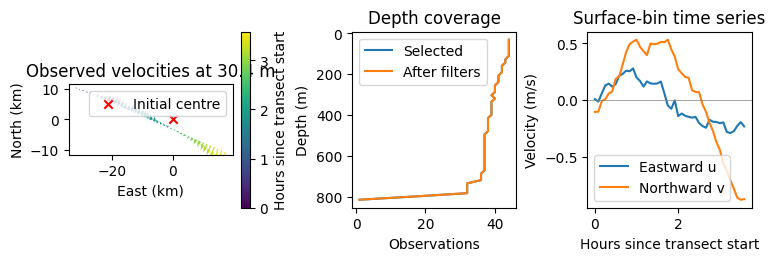

In [6]:
# ACTIVE_TRANSECT = "F2"  # Murphy: M1/M2; Freddy: F1-F9
run = runs[ACTIVE_TRANSECT]
data, coverage = run["data"], run["coverage"]
results, samples = run["results"], run["samples"]
display(pd.Series(run["audit"], name=ACTIVE_TRANSECT))
esp.report(results)
columns = ["depth_m", "status", "n_obs", "n_core", "inner_valid", "valid",
           "xc_lon", "yc_lat", "inner_R2", "Rc_m", "peak_bracketed", "vector_R2"]
with pd.option_context("display.max_rows", 60):
    display(results[columns].round(4))
esp.plot_sampling(data, coverage)
plt.show()


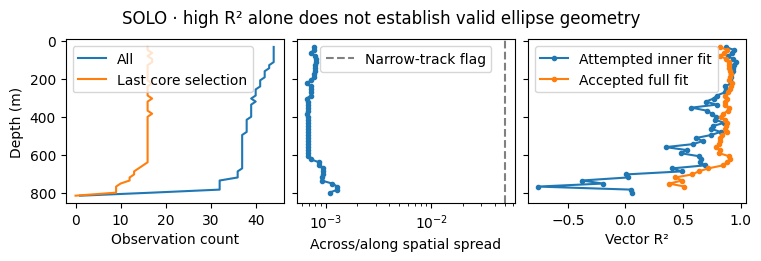

In [7]:
esp.plot_diagnostics(results)
plt.show()


## Vertical centre trajectory and parameters

Offset profiles use geographic east/north coordinates and increase from shallow to deep. They are distinct from the climatology's saved deep-to-shallow delta tilt. SOLO imposes axis ratio 1; `zeta = 2*Omega`. Gaussian `Rc` is not the same quantity as a paper-reported eddy radius or diameter. A failure in the outer stage does not erase an accepted inner centre.


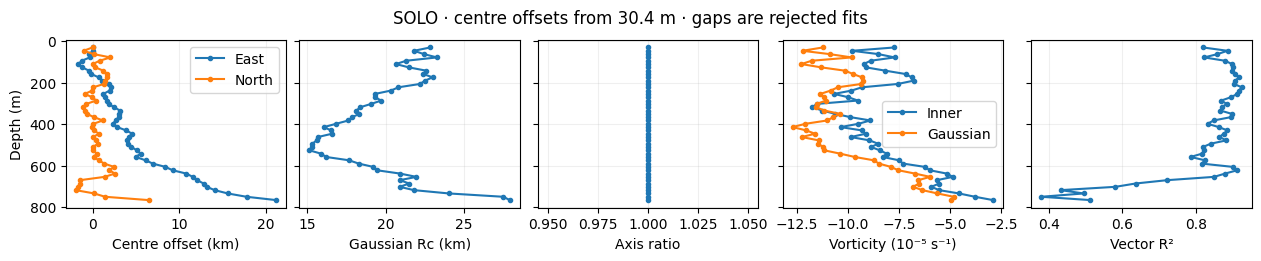

In [8]:
esp.plot_profiles(results)
plt.show()


## Horizontal reconstructions

Plots use the nearest measured level to each request, keeping failed levels visible. Black arrows are observed; grey arrows are reconstructed. Red marks the centre and `rho=Rc/sqrt(2)` contour where a Gaussian fit is accepted. Reconstruction off the sampled line is model-based extrapolation.


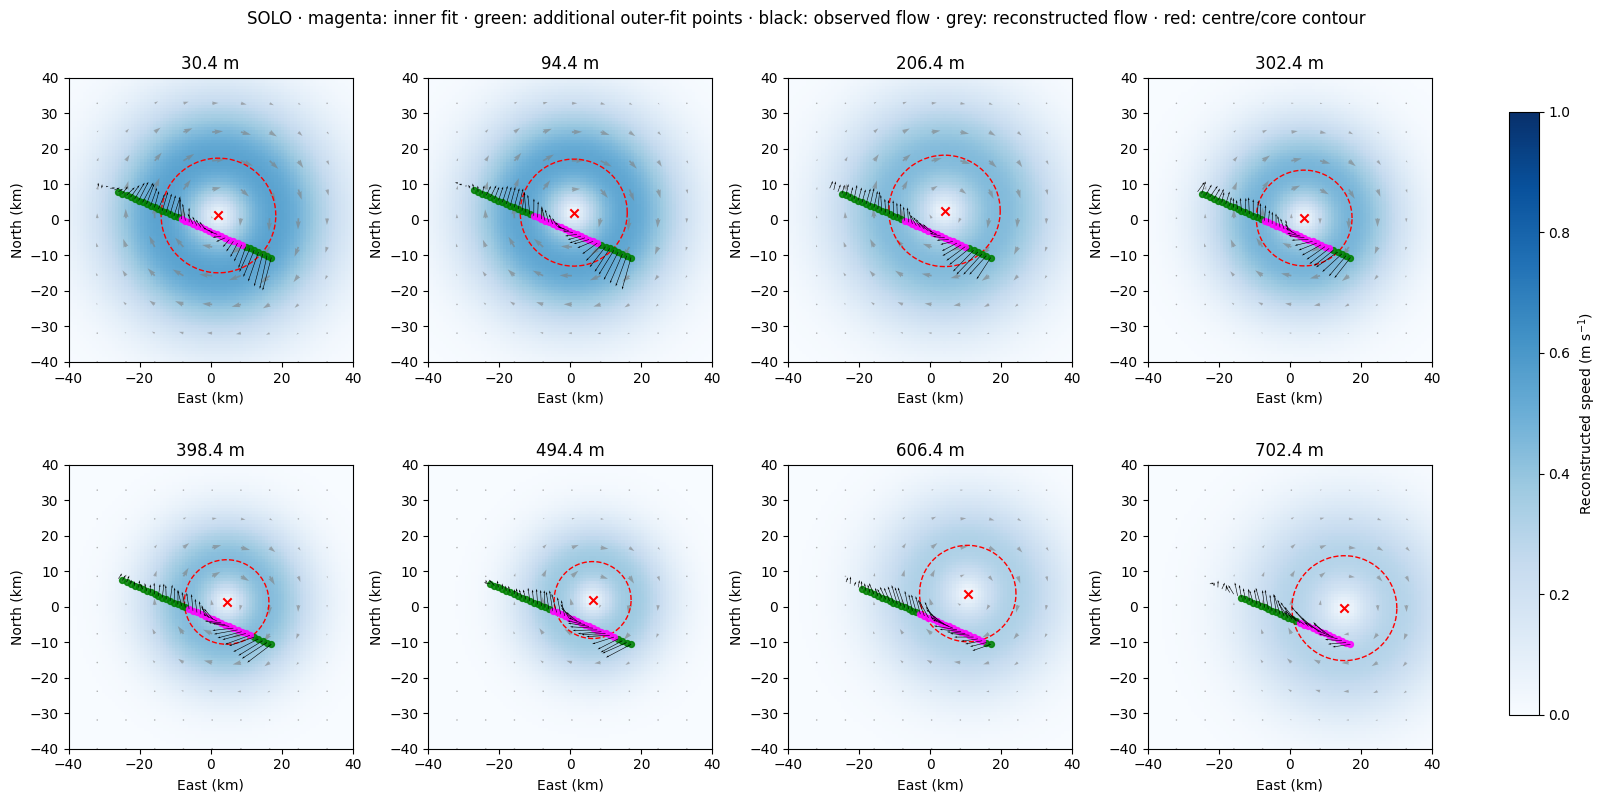

In [9]:
esp.plot_maps(results, samples, backend, depths=MAP_DEPTHS,
              half_width_km=HALF_WIDTH_KM, speed_max=VELOCITY_LIMIT)
plt.show()


## Surface satellite velocity and SOLO samples

The background shows OceanCurrent daily geostrophic velocity interpolated to the middle **observed ADCP timestamp** of `ACTIVE_TRANSECT`. The shallowest ADCP transect is overlaid: magenta points entered the SOLO inner fit, and green points are additional, circulation-sign-retained samples used in the Gaussian outer fit. Black is the ship transect. Missing daily maps are downloaded once and cached beside the CSV; the existing 3 June file is earlier than these transects.


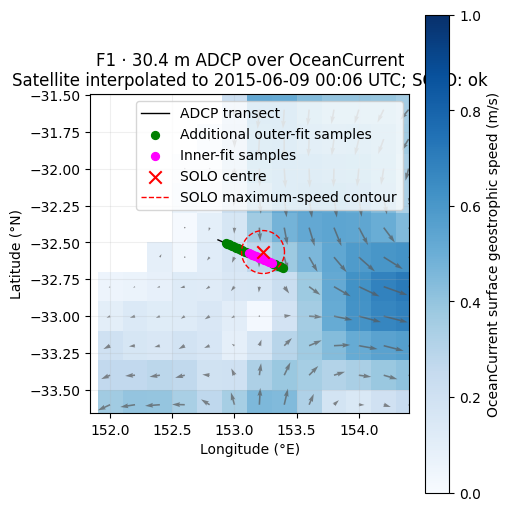

In [10]:
fig = esp.plot_solo_satellite_overlay(
    data, results, samples, DATA_PATH.parent, ACTIVE_TRANSECT,
    half_width_km=120, speed_max=VELOCITY_LIMIT)
plt.show()


## Three-dimensional structure

The centreline uses accepted inner fits; stacked contours and horizontal flow arrows appear only where the Gaussian stage is accepted. Where no radius is accepted, only the centreline is shown. Vertical scale is exaggerated. The deepest fitted bin does not establish the eddy bottom.


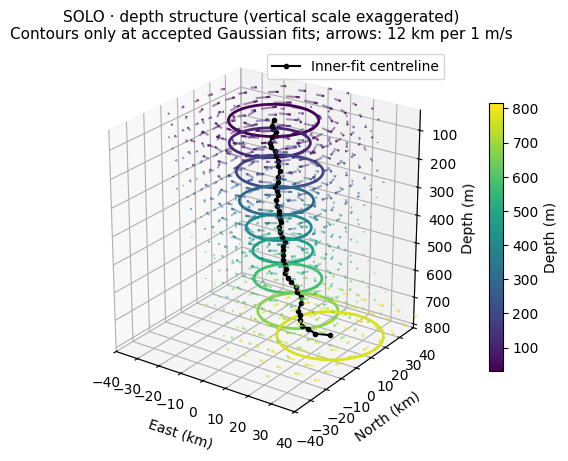

In [11]:
esp.plot_3d(results, backend, half_width_km=HALF_WIDTH_KM)
plt.show()


## Zonal and meridional sections

Fixed planes pass through the shallowest accepted inner centre. The zonal plane shows northward velocity `v`, and the meridional plane eastward velocity `u`. The centre paths are projections onto the planes; deeper centres need not lie within them. White depth rows are rejected Gaussian fits, with no interpolation across them. A crossing with no accepted Gaussian reconstruction produces an explanatory panel.


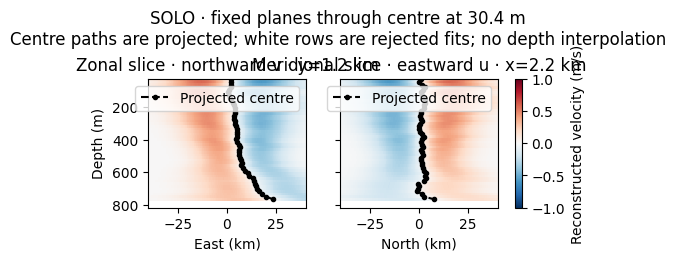

In [12]:
esp.plot_sections(results, backend, half_width_km=HALF_WIDTH_KM,
                  speed_max=VELOCITY_LIMIT)
plt.show()


## Export to scratch

Export all transects together, retaining IDs, actual UTC bounds, coordinates, depth support and failure statuses. Settings and per-crossing selection audits accompany the table.


In [13]:
SAVE_RESULTS = CONFIG["save_results"]
if SAVE_RESULTS:
    import json
    output = DATA_PATH.parent / "outputs"
    output.mkdir(parents=True, exist_ok=True)
    all_results.to_csv(output / f"{EDDY.lower()}_solo_depth_fits.csv", index=False)
    provenance = dict(eddy=EDDY, config_path=str(CONFIG_PATH), transects_config_path=str(TRANSECTS_PATH), data_path=str(DATA_PATH),
                      backend=backend_info, fit_settings=FIT,
                      transects=transects.reset_index().to_dict(orient="records"),
                      selection={key: value["audit"] for key, value in runs.items()})
    (output / f"{EDDY.lower()}_solo_provenance.json").write_text(
        json.dumps(provenance, indent=2, default=str))
